# PanoraDent — initial data exploration

This notebook checks the dataset structure, image dimensions, YOLO annotations, class balance, and structured findings. It does **not** train a model.

**Expected location:** the notebook is in the GitHub repository root, with the dataset folder named `PanoraDent/`. If your folder is elsewhere, change `DATA_DIR` in the configuration cell.

In [8]:
from pathlib import Path
import sys
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from collections import Counter

import torch

# Notebook is in: project/notebooks/
PROJECT_ROOT = Path.cwd().parent

# Dataset is in: project/data/PanoraDent/
DATA_DIR = PROJECT_ROOT / "data" / "PanoraDent"

assert DATA_DIR.exists(), f"Dataset not found: {DATA_DIR}"
assert (DATA_DIR / "images").exists()

print("Project root:", PROJECT_ROOT)
print("Dataset:", DATA_DIR)

Project root: c:\Users\Katharina Ring\Documents\ToothFairyVision
Dataset: c:\Users\Katharina Ring\Documents\ToothFairyVision\data\PanoraDent


## 1. PyTorch and compute device

This only selects the available device. No model is created and no GPU memory-intensive work is started.

In [9]:
print("PyTorch:", torch.__version__)
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    print("CUDA:", torch.version.cuda)
    print("GPU:", torch.cuda.get_device_name(0))
elif getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
    print("Using Apple Silicon MPS")
else:
    DEVICE = torch.device("cpu")
    print("CUDA/MPS unavailable; using CPU")

print("Selected device:", DEVICE)

PyTorch: 2.15.0+cpu
CUDA/MPS unavailable; using CPU
Selected device: cpu


## 2. Read configuration and split files

In [10]:
with open(DATA_DIR / "data.yaml", "r", encoding="utf-8") as f:
    data_config = yaml.safe_load(f)

names = data_config.get("names", {})
if isinstance(names, list):
    CLASS_NAMES = {i: name for i, name in enumerate(names)}
else:
    CLASS_NAMES = {int(k): v for k, v in names.items()}

print("Configured classes:")
for class_id, class_name in sorted(CLASS_NAMES.items()):
    print(f"  {class_id:>2}: {class_name}")

split_files = {}
for split in ["train", "valid", "test"]:
    path = DATA_DIR / "splits" / f"{split}.txt"
    split_files[split] = [x.strip() for x in path.read_text().splitlines() if x.strip()]
    print(f"{split:>5}: {len(split_files[split]):,} images")

Configured classes:
   0: Attrition
   1: Cyst
   2: Dental Caries
   3: Endodontically Treated Tooth
   4: Impacted Third Molar
   5: Missing Tooth
   6: Periapical Abnormality
   7: Periapical Lesion
   8: Periodontal Pocket
   9: Retained Root
  10: Tooth Fracture
train: 915 images
valid: 191 images
 test: 189 images


## 3. Metadata and basic integrity checks

The metadata CSV is useful for checking hospital, image resolution, annotation batch, and split composition.

In [11]:
metadata_path = DATA_DIR / "metadata" / "image_metadata.csv"
metadata = pd.read_csv(metadata_path)
display(metadata.head())
print("Rows:", len(metadata))
print("Columns:", metadata.columns.tolist())

for col in ["split", "hospital", "resolution_group", "annotation_batch"]:
    if col in metadata.columns:
        print(f"\n{col} counts:")
        display(metadata[col].value_counts(dropna=False).to_frame("images"))

image_paths = sorted((DATA_DIR / "images").glob("*.jpg"))
label_paths = sorted((DATA_DIR / "labels").glob("*.txt"))
print(f"JPEG images: {len(image_paths):,}")
print(f"TXT label files: {len(label_paths):,}")
print("Images without corresponding label file:",
      sum(not (DATA_DIR / "labels" / f"{p.stem}.txt").exists() for p in image_paths))

,Image_ID,hospital,width,height,resolution_group,annotation_batch,n_boxes,split,fold
0,OPG_0001.jpg,North East Medical College Hospital,2048,1096,G2,A,11,train,1
1,OPG_0002.jpg,North East Medical College Hospital,2048,939,G2,A,2,train,1
2,OPG_0003.jpg,Mount Adora Hospital,4124,2020,G1,B,4,valid,3
3,OPG_0004.jpg,North East Medical College Hospital,2048,1130,G2,A,6,train,4
4,OPG_0005.jpg,North East Medical College Hospital,2048,1052,G2,A,5,test,0


Rows: 1295
Columns: ['Image_ID', 'hospital', 'width', 'height', 'resolution_group', 'annotation_batch', 'n_boxes', 'split', 'fold']

split counts:


,images
split,
train,915
valid,191
test,189



hospital counts:


,images
hospital,
Mount Adora Hospital,870
North East Medical College Hospital,425



resolution_group counts:


,images
resolution_group,
G1,894
G2,401



annotation_batch counts:


,images
annotation_batch,
B,870
A,425


JPEG images: 1,295
TXT label files: 1,295
Images without corresponding label file: 0


## 4. Inspect image dimensions and pixel values

The dataset contains multiple export sizes. This cell measures the actual image dimensions rather than assuming a single input size.

Distinct image dimensions: 131


,width,height,count
0,4124,2020,894
1,2048,1086,11
2,2048,1087,10
3,2048,1081,9
4,2048,1098,9
5,2048,1071,9
6,2048,1085,8
7,2048,1062,8
8,2048,1084,8
9,2048,1066,7


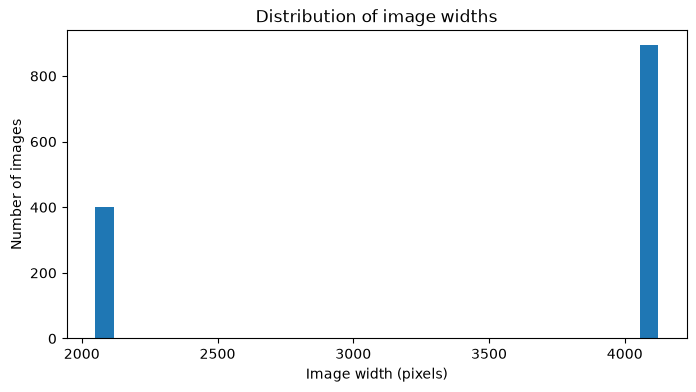

In [12]:
dimension_counts = Counter()
for path in image_paths:
    with Image.open(path) as im:
        dimension_counts[im.size] += 1

dimension_df = pd.DataFrame(
    [{"width": w, "height": h, "count": n} for (w, h), n in dimension_counts.items()]
).sort_values("count", ascending=False).reset_index(drop=True)

print("Distinct image dimensions:", len(dimension_df))
display(dimension_df.head(20))

plt.figure(figsize=(8, 4))
plt.hist([Image.open(p).size[0] for p in image_paths], bins=30)
plt.xlabel("Image width (pixels)")
plt.ylabel("Number of images")
plt.title("Distribution of image widths")
plt.show()

## 5. View radiographs

Change `IMAGE_ID` to any image stem, e.g. `OPG_0001`. This displays the original image without resizing.

Image: OPG_0001 | size: (2048, 1096)


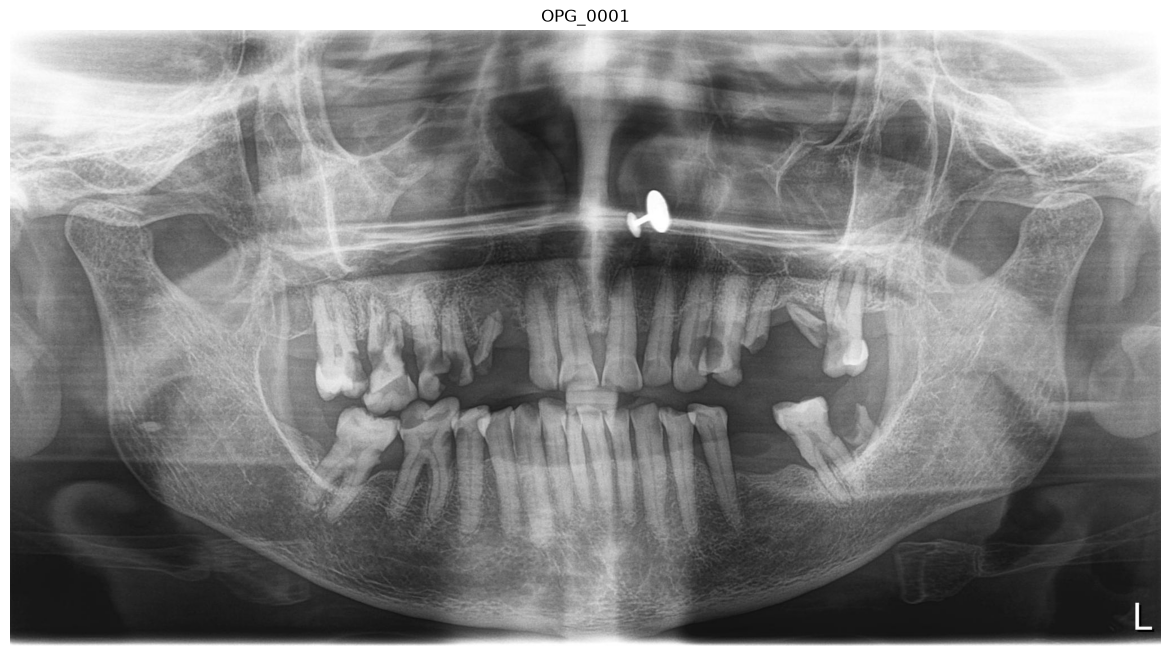

In [13]:
IMAGE_ID = image_paths[0].stem  # edit this, e.g. "OPG_0001"
image_path = DATA_DIR / "images" / f"{IMAGE_ID}.jpg"

with Image.open(image_path) as im:
    image = im.convert("RGB")
    print("Image:", IMAGE_ID, "| size:", image.size)
    plt.figure(figsize=(16, 8))
    plt.imshow(image)
    plt.axis("off")
    plt.title(IMAGE_ID)
    plt.show()

## 6. Parse and inspect YOLO bounding-box labels

YOLO format is `class_id x_center y_center width height`, with coordinates normalised to [0, 1]. The plot below converts these values to pixel coordinates for display.

<Axes: title={'center': 'OPG_0001 — 11 boxes'}>

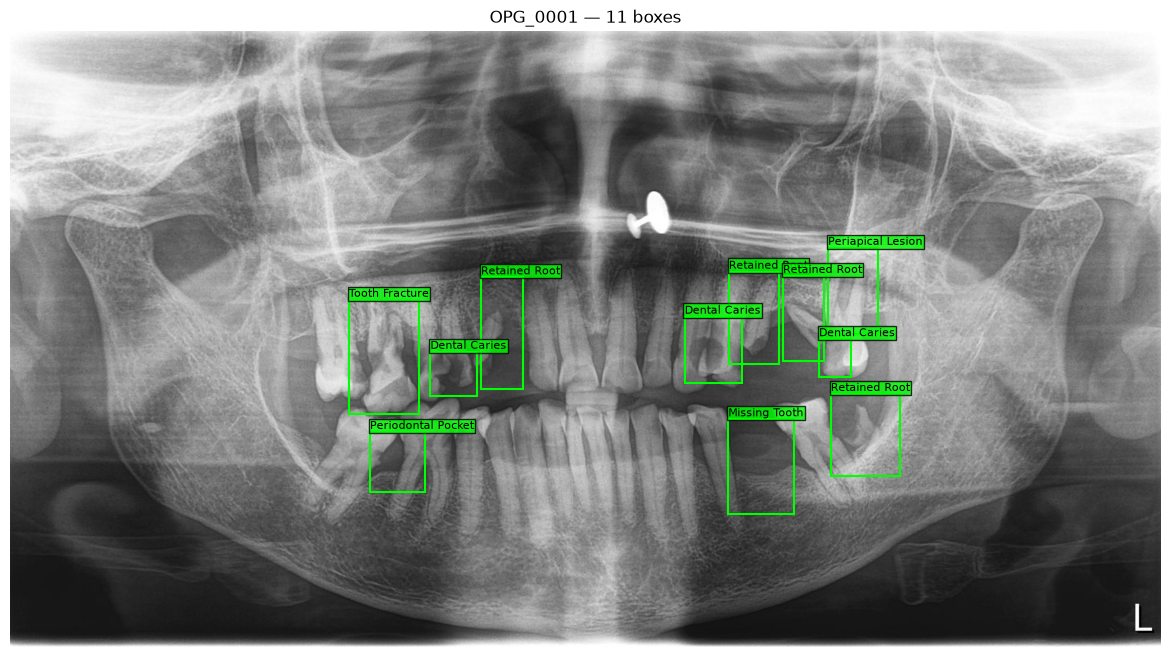

In [14]:
def read_yolo_label(label_path):
    rows = []
    if not label_path.exists():
        return np.empty((0, 5), dtype=float)
    for line in label_path.read_text().splitlines():
        if line.strip():
            values = [float(v) for v in line.split()]
            if len(values) != 5:
                raise ValueError(f"Unexpected label row in {label_path}: {line}")
            rows.append(values)
    return np.asarray(rows, dtype=float).reshape(-1, 5)

def show_image_with_boxes(image_id, ax=None):
    image_file = DATA_DIR / "images" / f"{image_id}.jpg"
    label_file = DATA_DIR / "labels" / f"{image_id}.txt"
    img = Image.open(image_file).convert("RGB")
    w, h = img.size
    labels = read_yolo_label(label_file)

    if ax is None:
        fig, ax = plt.subplots(figsize=(16, 8))
    ax.imshow(img)
    for row in labels:
        cls, xc, yc, bw, bh = row
        x0 = (xc - bw / 2) * w
        y0 = (yc - bh / 2) * h
        rect = plt.Rectangle((x0, y0), bw * w, bh * h,
                             fill=False, edgecolor="lime", linewidth=1.5)
        ax.add_patch(rect)
        class_name = CLASS_NAMES.get(int(cls), f"class {int(cls)}")
        ax.text(x0, max(0, y0 - 5), class_name, color="black", fontsize=8,
                bbox=dict(facecolor="lime", alpha=0.8, pad=1))
    ax.set_title(f"{image_id} — {len(labels)} boxes")
    ax.axis("off")
    return ax

show_image_with_boxes(IMAGE_ID)

## 7. Class frequencies and annotation coverage

These counts are recomputed from the YOLO text files. They should be broadly consistent with the dataset documentation.

,class_id,class_name,boxes,images
5,5,Missing Tooth,3628,913
2,2,Dental Caries,1281,658
3,3,Endodontically Treated Tooth,1059,313
4,4,Impacted Third Molar,1043,552
9,9,Retained Root,781,281
8,8,Periodontal Pocket,192,33
7,7,Periapical Lesion,97,79
10,10,Tooth Fracture,62,46
0,0,Attrition,28,16
6,6,Periapical Abnormality,23,15


Total boxes: 8,204
Images with no boxes: 37 / 1,295


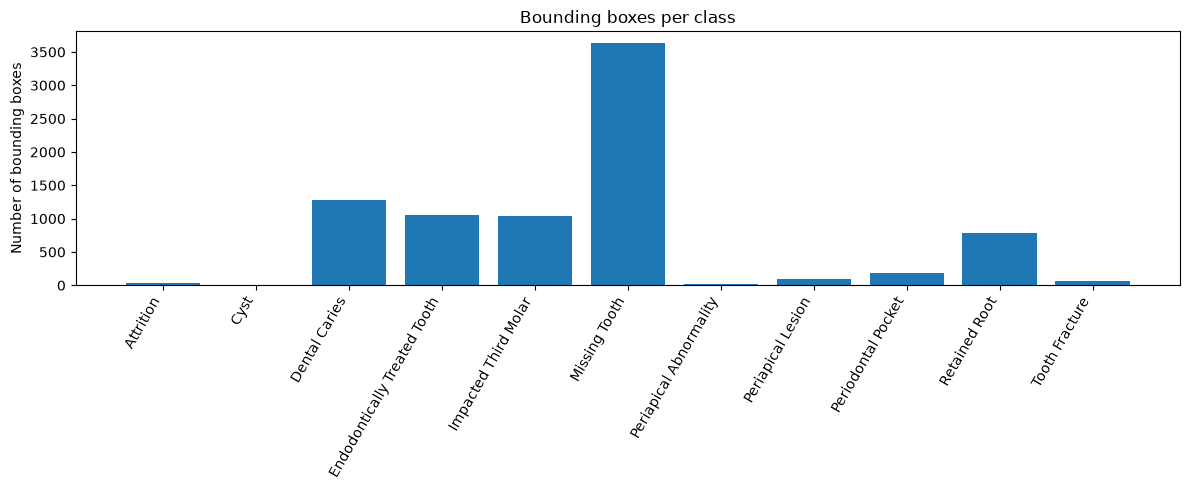

In [15]:
class_box_counts = Counter()
images_with_class = Counter()
images_without_boxes = 0
total_boxes = 0

for image_file in image_paths:
    labels = read_yolo_label(DATA_DIR / "labels" / f"{image_file.stem}.txt")
    if len(labels) == 0:
        images_without_boxes += 1
    total_boxes += len(labels)
    present_classes = set()
    for cls in labels[:, 0].astype(int):
        class_box_counts[cls] += 1
        present_classes.add(cls)
    for cls in present_classes:
        images_with_class[cls] += 1

class_summary = pd.DataFrame([
    {
        "class_id": i,
        "class_name": CLASS_NAMES.get(i, f"class {i}"),
        "boxes": class_box_counts[i],
        "images": images_with_class[i],
    }
    for i in sorted(set(CLASS_NAMES) | set(class_box_counts))
])
display(class_summary.sort_values("boxes", ascending=False))

print(f"Total boxes: {total_boxes:,}")
print(f"Images with no boxes: {images_without_boxes:,} / {len(image_paths):,}")

plt.figure(figsize=(12, 5))
plt.bar(class_summary["class_name"], class_summary["boxes"])
plt.xticks(rotation=60, ha="right")
plt.ylabel("Number of bounding boxes")
plt.title("Bounding boxes per class")
plt.tight_layout()
plt.show()

## 8. Compare class frequencies across the fixed splits

In [16]:
split_class_counts = []
for split, entries in split_files.items():
    for entry in entries:
        image_id = Path(entry).stem
        labels = read_yolo_label(DATA_DIR / "labels" / f"{image_id}.txt")
        for cls, count in Counter(labels[:, 0].astype(int)).items():
            split_class_counts.append({"split": split, "class_id": cls, "boxes": count})

split_counts = pd.DataFrame(split_class_counts)
if not split_counts.empty:
    split_pivot = split_counts.groupby(["split", "class_id"])["boxes"].sum().unstack(fill_value=0)
    split_pivot.columns = [CLASS_NAMES.get(int(c), str(c)) for c in split_pivot.columns]
    display(split_pivot)

,Attrition,Cyst,Dental Caries,Endodontically Treated Tooth,Impacted Third Molar,Missing Tooth,Periapical Abnormality,Periapical Lesion,Periodontal Pocket,Retained Root,Tooth Fracture
split,,,,,,,,,,,
test,2,0,186,137,149,499,2,13,19,105,9
train,23,7,912,753,735,2676,17,68,120,572,46
valid,3,3,183,169,159,453,4,16,53,104,7


## 9. Inspect structured findings

These variables are machine-derived and have not been dentist-reviewed. Check the data dictionary before interpreting individual columns.

In [17]:
findings_path = DATA_DIR / "structured_findings" / "structured_findings.csv"
dictionary_path = DATA_DIR / "structured_findings" / "data_dictionary.csv"

findings = pd.read_csv(findings_path)
dictionary = pd.read_csv(dictionary_path)

print("Structured findings shape:", findings.shape)
display(findings.head())
print("Data dictionary:")
display(dictionary.head(30))

# Quick missingness overview
missingness = findings.isna().mean().sort_values(ascending=False)
display(missingness[missingness > 0].to_frame("fraction_missing"))

Structured findings shape: (1295, 15)


,Image_ID,Total present teeth,Total missing teeth,Total present maxillary teeth,Total present mandibular teeth,Total teeth with dental caries,Total impacted teeth,Impaction location,Impacted teeth (FDI),Total retained roots,Total teeth with periapical abnormalities,Endodontic treatment status,Endodontically treated teeth (FDI),Uncertainty flags,Provenance
0,OPG_0001.jpg,25,7,12,13,3,0,No impacted teeth,NaN,4,1,No restoration,NaN,tooth count: 32 - present = 7 but 1 human miss...,Machine-derived from human boxes + FDI tooth d...
1,OPG_0002.jpg,30,2,15,15,0,0,No impacted teeth,NaN,0,0,No restoration,NaN,3 teeth detected with confidence < 0.5,Machine-derived from human boxes + FDI tooth d...
2,OPG_0003.jpg,12,20,3,9,1,0,No impacted teeth,NaN,0,0,No restoration,NaN,tooth count: 32 - present = 20 but 3 human mis...,Machine-derived from human boxes + FDI tooth d...
3,OPG_0004.jpg,28,4,14,14,1,0,No impacted teeth,NaN,3,0,No restoration,NaN,tooth count: 32 - present = 4 but 0 human miss...,Machine-derived from human boxes + FDI tooth d...
4,OPG_0005.jpg,25,7,15,10,0,0,No impacted teeth,NaN,0,0,No restoration,NaN,NaN,Machine-derived from human boxes + FDI tooth d...


Data dictionary:


,column,type,definition,source
0,Image_ID,string,File name in images/ (OPG_NNNN.jpg),all
1,Total present teeth,int 0-32,Numbered tooth positions found by the FDI toot...,detector + human boxes
2,Total missing teeth,int 0-32,32 - Total present teeth; therefore includes a...,derived
3,Total present maxillary teeth,int 0-16,Present teeth in FDI quadrants 1-2,detector
4,Total present mandibular teeth,int 0-16,Present teeth in FDI quadrants 3-4,detector
5,Total teeth with dental caries,int,Teeth carrying a human Dental Caries box; seve...,human boxes + detector
6,Total impacted teeth,int 0-4,Impacted third molars (human boxes). Other imp...,human boxes
7,Impaction location,text,"Anatomical names of impacted third molars, "";""...",human boxes + detector
8,Impacted teeth (FDI),text,"Same teeth as FDI numbers (18, 28, 38, 48), "";...",derived
9,Total retained roots,int,"As caries, for Retained Root boxes",human boxes + detector


,fraction_missing
Endodontically treated teeth (FDI),0.758301
Uncertainty flags,0.695753
Impacted teeth (FDI),0.573745


## 10. Preview a small batch with the reusable PyTorch Dataset

The companion `panoradent_data.py` file provides a basic Dataset, YOLO-label parser, collate function, and DataLoader factory. Since original OPG dimensions vary, batches are returned as **lists** of images and targets rather than stacked tensors. Start with `batch_size=1`.

In [19]:
# If panoradent_data.py is in the repository root:
sys.path.insert(0, str(PROJECT_ROOT))
from panoradent_data import (
    get_device, load_yolo_labels, PanoraDentDataset,
    detection_collate_fn, create_dataloader
)

DEVICE = get_device()
train_dataset = PanoraDentDataset(DATA_DIR, split="train")
print("Train dataset size:", len(train_dataset))

image_tensor, target = train_dataset[0]
print("Image tensor:", tuple(image_tensor.shape), image_tensor.dtype,
      f"range=({image_tensor.min():.3f}, {image_tensor.max():.3f})")
print("Boxes:", tuple(target["boxes"].shape))
print("Labels:", target["labels"].tolist())
print("Image path:", target["image_path"])

train_loader = create_dataloader(
    DATA_DIR, split="train", batch_size=1, num_workers=0
)
batch_images, batch_targets = next(iter(train_loader))
print("Batch image count:", len(batch_images))
print("First batch image shape:", tuple(batch_images[0].shape))
print("First target keys:", batch_targets[0].keys())

Train dataset size: 915
Image tensor: (3, 1096, 2048) torch.float32 range=(0.000, 1.000)
Boxes: (11, 4)
Labels: [7, 2, 9, 2, 9, 2, 10, 9, 5, 8, 9]
Image path: c:\Users\Katharina Ring\Documents\ToothFairyVision\data\PanoraDent\images\OPG_0001.jpg
Batch image count: 1
First batch image shape: (3, 2020, 4124)
First target keys: dict_keys(['boxes', 'labels', 'image_id', 'image_path'])


## 11. Visualise an image returned by the Dataset

The Dataset returns normalised `xywh` boxes, matching the original YOLO annotations.

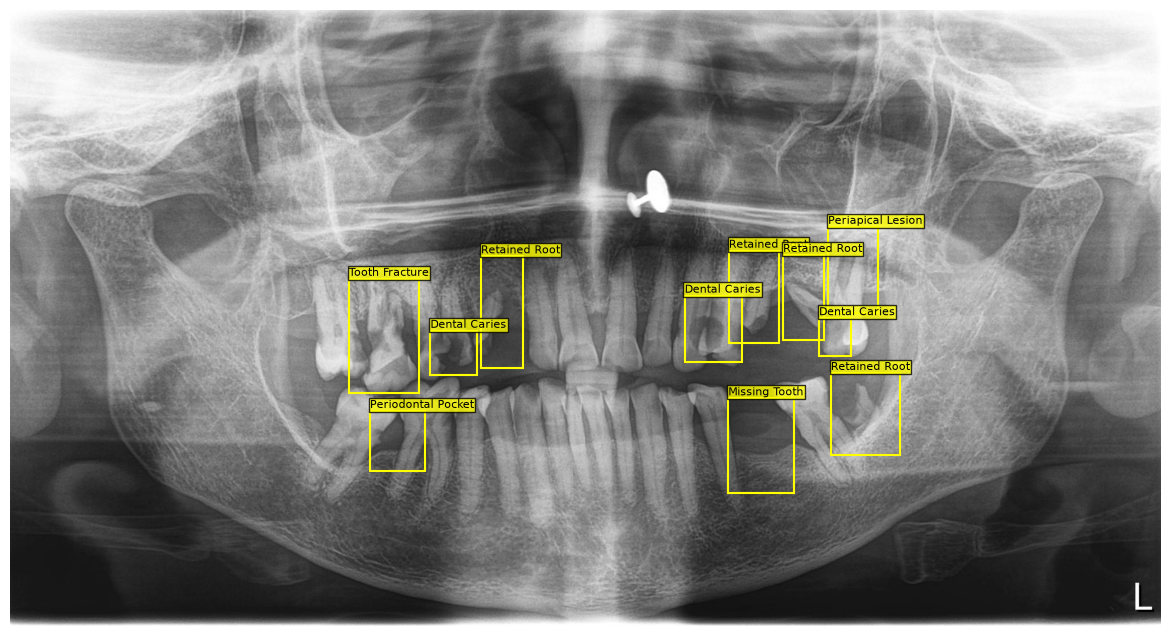

In [20]:
img_tensor, target = train_dataset[0]
img_np = img_tensor.permute(1, 2, 0).numpy()
h, w = img_np.shape[:2]

fig, ax = plt.subplots(figsize=(16, 8))
ax.imshow(img_np)
for box, cls in zip(target["boxes"].numpy(), target["labels"].numpy()):
    xc, yc, bw, bh = box
    x0, y0 = (xc - bw / 2) * w, (yc - bh / 2) * h
    ax.add_patch(plt.Rectangle((x0, y0), bw * w, bh * h,
                               fill=False, edgecolor="yellow", linewidth=1.5))
    ax.text(x0, max(0, y0 - 5), CLASS_NAMES.get(int(cls), str(cls)),
            color="black", fontsize=8,
            bbox=dict(facecolor="yellow", alpha=0.8, pad=1))
ax.axis("off")
plt.show()

## Notes before modelling

- The fixed train/valid/test split is image-level; patient-level separation cannot be guaranteed because patient IDs are unavailable.
- Hospital and annotation batch are confounded in this release.
- The structured findings are machine-derived and should not be treated as dentist-verified ground truth.
- Keep the original image dimensions/geometry in mind when choosing a detector's resizing strategy. The starter Dataset deliberately does not resize images.
- For initial exploration, inspect examples from each target class and review the rare classes manually.